## Experiment Setup: uVote-Based Few-Shot Improvement

In [ ]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import plotly.graph_objects as go
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Path
PROJECT_ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(PROJECT_ROOT))

from models.rnn_uvote import VanillaRNN_UVOTE
from utils.reproducibility_utils import seed_everything
from utils.dataloadinguvote import load_data, load_test_data, feature_names


In [ ]:
# Set random seed for reproducibility across runs
seed_everything(42)  # for reproducibility

## Data loading (Train / validation loaders)

In [8]:
print("Loading train data...")
train_dataloader, val_dataloader, pipeline = load_data(
    train_path = PROJECT_ROOT / "datasets_challenge" / "train",  # Path to training data
    train_ratio = 0.98,  # Use 98% for training, 2% for validation
    batchsize = 64,  # Number of samples per batch
    columns_to_standardize = feature_names,  # Option to specify which columns to standardize
    columns_to_drop = ["sideSlip", "vyCG", "time", "longitude","latitude"],  # Remove these from features
    sequence_length = 20,  # Number of time steps in each sequence (t-19 to t0)
    threshold = True,  # Enable velocity thresholding
    threshold_value = 3.0,  # Only keep samples where vehicle speed > 3 m/s
    threshold_column = "vxCG",  # Column to apply threshold on (longitudinal velocity)
    target = "sideSlip",  # The variable we want to predict
    scaling = True,  # Apply standardization to features
    seed = 42,  # Random seed for train/val split
)

Loading train data...
c:\mait_g2_drift_challenge\datasets_challenge\train\train_part_001.csv
c:\mait_g2_drift_challenge\datasets_challenge\train\train_part_002.csv
c:\mait_g2_drift_challenge\datasets_challenge\train\train_part_003.csv
c:\mait_g2_drift_challenge\datasets_challenge\train\train_part_004.csv
c:\mait_g2_drift_challenge\datasets_challenge\train\train_part_005.csv
c:\mait_g2_drift_challenge\datasets_challenge\train\train_part_006.csv
c:\mait_g2_drift_challenge\datasets_challenge\train\train_part_007.csv
c:\mait_g2_drift_challenge\datasets_challenge\train\train_part_008.csv
c:\mait_g2_drift_challenge\datasets_challenge\train\train_part_009.csv
c:\mait_g2_drift_challenge\datasets_challenge\train\train_part_010.csv
c:\mait_g2_drift_challenge\datasets_challenge\train\train_part_011.csv
c:\mait_g2_drift_challenge\datasets_challenge\train\train_part_012.csv
c:\mait_g2_drift_challenge\datasets_challenge\train\train_part_013.csv
c:\mait_g2_drift_challenge\datasets_challenge\train\tra

## U-Vote loss definition

In [10]:
def weighted_heteroscedastic_nll(mu, log_var, y, w):
    """
    U-Vote loss for imbalanced regression

    mu:      (B, 1) predicted mean
    log_var: (B, 1) predicted log variance
    y:       (B, 1) ground truth
    w:       (B, 1) sample weights (few > medium > many)
    """

    # stability
    log_var = torch.clamp(log_var, min=-5.0, max=5.0)

    # inverse variance (confidence)
    inv_var = torch.exp(-log_var)

    # Gaussian negative log-likelihood
    nll = 0.5 * inv_var * (y - mu) ** 2 + 0.5 * log_var

    # U-Vote weighting
    return (w * nll).mean()


## Model Architecture

In [11]:
from sklearn.metrics import mean_absolute_error

device = "cuda" if torch.cuda.is_available() else "cpu"

model = VanillaRNN_UVOTE(
    input_size=22,          # number of features
    hidden_size=64,
    num_layers=1,
    dropout=0.0
).to(device)

criterion = weighted_heteroscedastic_nll  # uvote loss
optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)


## Training and Validation

In [8]:
num_epochs = 30

for epoch in range(num_epochs):
    model.train()
    losses = []

    for X, y, weights in train_dataloader:
        X = X.to(device)                        # (B, T, F)
        y = y.to(device).view(-1, 1)            # (B, 1)

        # uvote-style: weights come as list OR tensor
        if isinstance(weights, list):
            w = weights[0].to(device)
        else:
            w = weights.to(device)

        w = w.view(-1, 1)                       # (B, 1)

        mu, log_var = model(X)

        loss = weighted_heteroscedastic_nll(mu, log_var, y, w)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        losses.append(loss.item())
        
    model.eval()
    val_losses = []
    val_maes = []
    
    with torch.no_grad():
        for X_val, y_val, weights_val in val_dataloader:
            X_val = X_val.to(device)
            y_val = y_val.to(device).view(-1, 1)

            if isinstance(weights_val, list):
                w_val = weights_val[0].to(device)
            else:
                w_val = weights_val.to(device)

            w_val = w_val.view(-1, 1)

            mu_val, log_var_val = model(X_val)

            val_loss = weighted_heteroscedastic_nll(mu_val, log_var_val, y_val, w_val)
            val_losses.append(val_loss.item())

            mae = mean_absolute_error(y_val.cpu().numpy(), mu_val.cpu().numpy())
            val_maes.append(mae)
    print(f"Epoch {epoch+1:02d} |Train Loss: {np.mean(losses):.4f} | Val Loss: {np.mean(val_losses):.4f} | Val MAE: {np.mean(val_maes):.4f}")

Epoch 01 |Train Loss: -0.0111 | Val Loss: -0.7123 | Val MAE: 0.2837
Epoch 02 |Train Loss: -0.8171 | Val Loss: -0.9989 | Val MAE: 0.2243
Epoch 03 |Train Loss: -1.0270 | Val Loss: -1.1336 | Val MAE: 0.2035
Epoch 04 |Train Loss: -1.1281 | Val Loss: -1.2489 | Val MAE: 0.1857
Epoch 05 |Train Loss: -1.2002 | Val Loss: -1.3291 | Val MAE: 0.1754
Epoch 06 |Train Loss: -1.2537 | Val Loss: -1.3413 | Val MAE: 0.1770
Epoch 07 |Train Loss: -1.2870 | Val Loss: -1.3373 | Val MAE: 0.1786
Epoch 08 |Train Loss: -1.3060 | Val Loss: -1.4206 | Val MAE: 0.1623
Epoch 09 |Train Loss: -1.3403 | Val Loss: -1.4568 | Val MAE: 0.1595
Epoch 10 |Train Loss: -1.3652 | Val Loss: -1.4831 | Val MAE: 0.1564
Epoch 11 |Train Loss: -1.3810 | Val Loss: -1.5010 | Val MAE: 0.1532
Epoch 12 |Train Loss: -1.4033 | Val Loss: -1.5105 | Val MAE: 0.1521
Epoch 13 |Train Loss: -1.4174 | Val Loss: -1.5140 | Val MAE: 0.1515
Epoch 14 |Train Loss: -1.4334 | Val Loss: -1.5154 | Val MAE: 0.1508
Epoch 15 |Train Loss: -1.4506 | Val Loss: -1.520

## Error vs Uncertainity Plotting

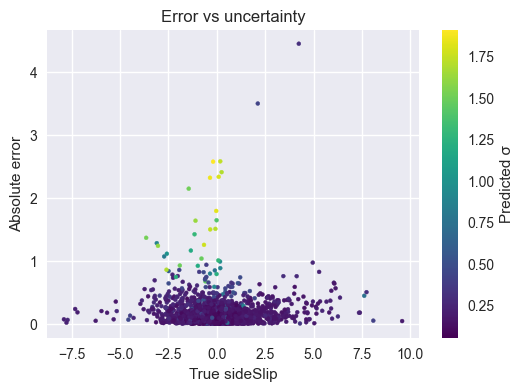

In [ ]:
model.eval()
mus, sigmas, ys = [], [], []

with torch.no_grad():
    for X, y, _ in val_dataloader:
        X = X.to(device)
        mu, log_var = model(X)

        sigma = torch.exp(0.5 * log_var)

        mus.extend(mu.cpu().numpy().reshape(-1))
        sigmas.extend(sigma.cpu().numpy().reshape(-1))
        ys.extend(y.numpy().reshape(-1))

mus = np.array(mus)
sigmas = np.array(sigmas)
ys = np.array(ys)

plt.figure(figsize=(6,4))
plt.scatter(ys, np.abs(mus - ys), c=sigmas, cmap="viridis", s=8)
plt.colorbar(label="Predicted σ")
plt.xlabel("True sideSlip")
plt.ylabel("Absolute error")
plt.title("Error vs uncertainty")
plt.show()


## Ground Truth vs Prediction

In [ ]:
model.eval()

preds = []
ground_truths = []

with torch.no_grad():
    for X, y, *_ in val_dataloader:   # ignore weights if present
        X = X.to(device)
        y = y.to(device).view(-1, 1)

        mu, _ = model(X)              # 🔹 U-Vote: use mu only

        preds.append(mu.cpu().numpy().reshape(-1))
        ground_truths.append(y.cpu().numpy().reshape(-1))

# concatenate all batches
preds = np.concatenate(preds)
ground_truths = np.concatenate(ground_truths)

print("Validation MAE:", np.mean(np.abs(preds - ground_truths)))

# Plot
fig = go.Figure()
fig.add_trace(
    go.Scatter(
        y=ground_truths,
        mode="lines",
        name="Ground Truth",
        line=dict(color="blue")
    )
)
fig.add_trace(
    go.Scatter(
        y=preds,
        mode="lines",
        name="Prediction (μ)",
        line=dict(color="red"),
        opacity=0.8
    )
)

fig.update_layout(
    title="Validation: Ground Truth vs Predictions",
    xaxis_title="Sample Index",
    yaxis_title="Sideslip Angle (degrees)",
    width=1200,
    height=500
)

fig.show()


Validation MAE: 0.15429923
